# Lab Assignment 1 - Agglomerative Customer Segmentation
## JS08 - Hierarchical Clustering

**Name:** Tiara Febrianie  
**NIM:** 244107020097

All usable numeric variables in `CC_Customer_Dataset (1).csv` are used for clustering. The requested scatterplot uses `Avg_Credit_Limit` and `Total_Credit_Cards`.

Usable variables: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
Samples: 660


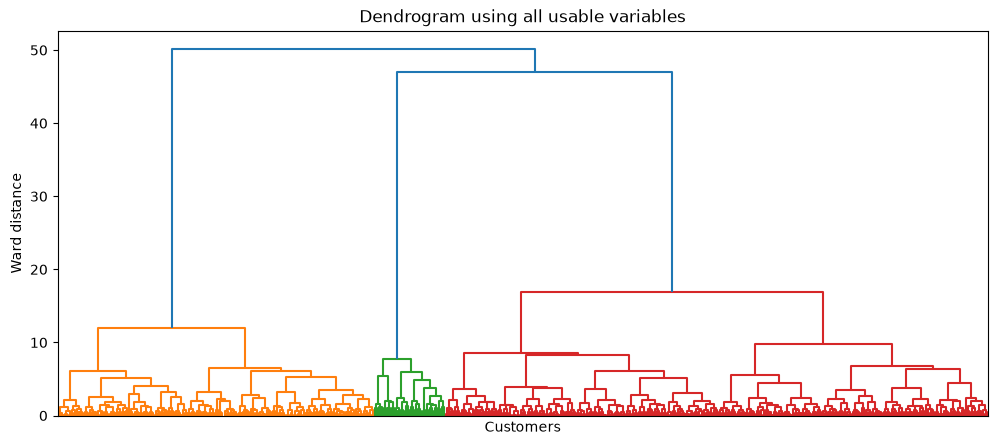

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

df = pd.read_csv('CC_Customer_Dataset (1).csv')
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
features = [column for column in numeric_columns if column not in ['Sl_No', 'Customer Key']]
X = df[features].dropna().to_numpy()
X_scaled = StandardScaler().fit_transform(X)
print(f'Usable variables: {features}')
print(f'Samples: {len(X_scaled)}')

plt.figure(figsize=(12, 5))
sch.dendrogram(sch.linkage(X_scaled, method='ward'), no_labels=True)
plt.title('Dendrogram using all usable variables')
plt.xlabel('Customers')
plt.ylabel('Ward distance')
plt.show()

,clusters,silhouette,DBI
0,2,0.417704,0.932640
1,3,0.514764,0.680960
2,4,0.348082,1.149303
3,5,0.256918,1.385112
4,6,0.226778,1.410876
5,7,0.216297,1.439434
6,8,0.218695,1.448888


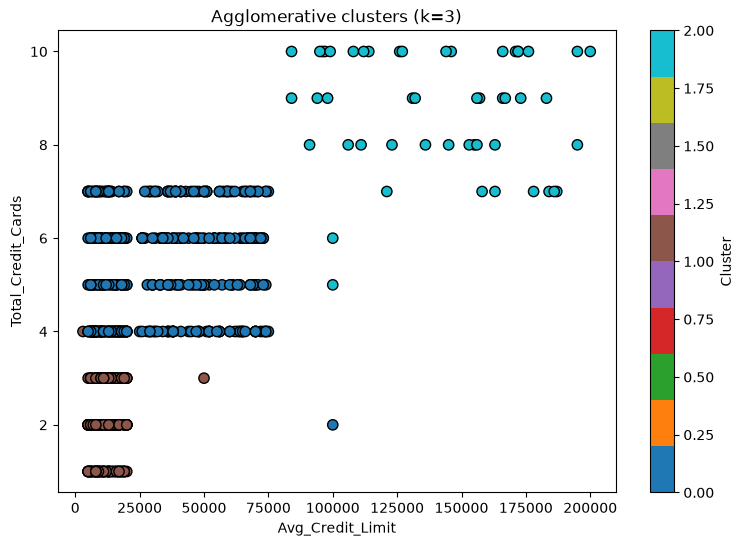

Silhouette score: 0.5148
Davies-Bouldin Index: 0.6810


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Cluster,,,,,
1,33851.95,5.52,3.49,0.98,1.99
2,12151.11,2.42,0.94,3.55,6.86
3,141040.00,8.74,0.60,10.90,1.08


In [4]:
rows = []
for k in range(2, 9):
    model = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    labels = model.fit_predict(X_scaled)
    rows.append({'clusters': k, 'silhouette': silhouette_score(X_scaled, labels),
                 'DBI': davies_bouldin_score(X_scaled, labels)})
selection = pd.DataFrame(rows)
display(selection)
best_k = int(selection.loc[selection['silhouette'].idxmax(), 'clusters'])
model = AgglomerativeClustering(n_clusters=best_k, metric='euclidean', linkage='ward')
labels = model.fit_predict(X_scaled)
df = df.loc[df[features].dropna().index].copy()
df['Cluster'] = labels + 1

plt.figure(figsize=(9, 6))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], c=labels, cmap='tab10', s=55, edgecolor='black')
plt.title(f'Agglomerative clusters (k={best_k})')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.colorbar(label='Cluster')
plt.show()

print(f'Silhouette score: {silhouette_score(X_scaled, labels):.4f}')
print(f'Davies-Bouldin Index: {davies_bouldin_score(X_scaled, labels):.4f}')
display(df.groupby('Cluster')[features].mean().round(2))

### Analysis
Standardization is applied so that the credit-limit scale does not dominate the visit/card-count variables. The selected `k` maximizes silhouette score in the tested range; DBI is reported alongside it, where lower is better. The scatterplot is a two-dimensional view of a model trained with every usable behavioral/financial variable.